# Word-level language modeling with a tiny RNN

This notebook follows the same teaching pattern as the other examples in the workspace: keep the idea concrete, inspect shapes, write the model in small pieces, and then train it on a real problem.

The task is simple but powerful: given a sequence of words, predict the next word. That is the core idea behind language models.

We will start with plain text, split it into word tokens, convert those tokens into integers, build a minimal recurrent model, and then see how the hidden state lets the network remember what came before.

## 1. Start with a small piece of text

A language model learns a conditional distribution:

given the words so far, what word is likely to come next?

For example, if the input is `The Lord of`, the next word might be `the`. More generally, the model sees a sequence of words and learns to predict the next token.

In [52]:
text = """Alice was beginning to get very tired of sitting by her sister on the bank,and of having nothing to do: once or twice she had peeped into the book her sister was reading, but it had no pictures or conversations in it, "and what is the use of a book," thought Alice "without pictures or conversation?\" """

with open('0305_kmeans_scratch.py', 'r') as f:
    text = f.read()

with open(r"C:\Users\101119\OneDrive\ePUBs\Books and Articles\The Lord of the rings\New Text Document.txt", 'r') as f:
    text = f.read()

# text = text.lower()
print(len(text))
print(text[:500])

2620690
 This tale grew in the telling, until it became a history of the Great War of the Ring and included many glimpses of the yet more ancient history that preceded it. It was begun soon after The Hobbit was written and before its publication in 1937; but I did not go on with this sequel, for I wished first to complete and set in order the mythology and legends of the Elder Days, which had then been taking shape for some years. I desired to do this for my own satisfaction, and I had little hope that 


## 2. Build the word vocabulary

A neural network cannot read raw text. It reads numbers. We split the text into word tokens and create a mapping from each unique token to an integer index.

This is the same idea as class labels in classification, except now the labels are words and punctuation attached to words.

In [53]:
tokens = text.split()
from collections import Counter

counts = Counter(tokens)

for limit in (1000, 3000, 5000, 10000):
    kept = {word for word, _ in counts.most_common(limit)}
    coverage = sum(counts[word] for word in kept) / len(tokens)
    print(f'{limit} words: {coverage:.1%} token coverage')


max_words = 5000
unk_token = '<unk>'
words = [unk_token] + [word for word, _ in counts.most_common() if word != unk_token][:max_words]

print('vocab size:', len(words))
print('first vocabulary entries:', words[:20])



stoi = {word: i for i, word in enumerate(words)}
itos = {i: word for word, i in stoi.items()}

print('index for first token:', stoi.get(tokens[0], stoi['<unk>']))
print('word back from index:', itos[stoi.get(tokens[0], stoi['<unk>'])])

1000 words: 73.3% token coverage
3000 words: 83.6% token coverage
5000 words: 87.9% token coverage
10000 words: 92.8% token coverage
vocab size: 5001
first vocabulary entries: ['<unk>', 'the', 'and', 'of', 'to', 'a', 'in', 'he', 'was', 'that', 'I', 'his', 'it', 'they', 'not', 'you', 'said', 'as', 'is', 'for']
index for first token: 394
word back from index: This


In [54]:
def encode(s):
    return [stoi.get(word, stoi['<unk>']) for word in s.split()]



def decode(ids):
    return ' '.join(itos[i] for i in ids)



example = ' '.join(tokens[:5])
encoded_example = encode(example)
print('encoded word ids:', encoded_example)
print('decoded back:', decode(encoded_example))

encoded word ids: [394, 693, 304, 6, 1]
decoded back: This tale grew in the


## 3. Turn text into supervised examples

A sequence model is trained on pairs of input and target sequences.

For the phrase `the quick brown fox`, the examples are:

- `the -> quick`
- `the quick -> brown`
- `the quick brown -> fox`

In other words, the target sequence is the source shifted by one word.

This is the heart of next-word prediction.

In [55]:
import torch

block_size = 32
encoded = torch.tensor(encode(text), dtype=torch.long)

x = encoded[:block_size]
y = encoded[1:block_size + 1]

print('x shape:', x.shape)
print('y shape:', y.shape)
print('x words:', decode(x.tolist()))
print('y words:', decode(y.tolist()))

x shape: torch.Size([32])
y shape: torch.Size([32])
x words: This tale grew in the <unk> until it became a history of the Great War of the Ring and <unk> many <unk> of the yet more ancient history that <unk> it. It
y words: tale grew in the <unk> until it became a history of the Great War of the Ring and <unk> many <unk> of the yet more ancient history that <unk> it. It was


## 4. Make batches

Training on a single long sequence of words is not efficient. Instead, we sample many random blocks from the text and train on them in batches.

This creates a dataset of shape `(batch, time)`. Each input position is a word token, and the target is the following word.

In [56]:
def get_batch(data, batch_size, block_size):
    starts = torch.randint(len(data) - block_size, (batch_size,))
    xb = torch.stack([data[s:s + block_size] for s in starts])
    yb = torch.stack([data[s + 1:s + 1 + block_size] for s in starts])
    return xb, yb

batch_size = 4
xb, yb = get_batch(encoded, batch_size, block_size)

print('xb shape:', xb.shape)
print('yb shape:', yb.shape)
for i in range(batch_size):
    print(f'example {i}:')
    print('input words :', decode(xb[i].tolist()))
    print('target words:', decode(yb[i].tolist()))
    print('-' * 30)

xb shape: torch.Size([4, 32])
yb shape: torch.Size([4, 32])
example 0:
input words : it for <unk> for ages folk in the Shire <unk> various <unk> some <unk> some <unk> But all <unk> agree that <unk> <unk> of <unk> in the Southfarthing first grew the true
target words: for <unk> for ages folk in the Shire <unk> various <unk> some <unk> some <unk> But all <unk> agree that <unk> <unk> of <unk> in the Southfarthing first grew the true <unk>
------------------------------
example 1:
input words : may long remember your words, <unk> For there is hope in them. Maybe a king has indeed returned to Gondor; or have you not heard the strange tidings that have come to
target words: long remember your words, <unk> For there is hope in them. Maybe a king has indeed returned to Gondor; or have you not heard the strange tidings that have come to the
------------------------------
example 2:
input words : and then only in hurried <unk> There was no sound but the sound of their own feet; the dull stump of

## 5. Start with a simple baseline

Before adding recurrence, let's build a deliberately weak model.

This model will look at only the current word and try to predict the next one. It cannot know what happened earlier in the sequence. That is the problem we need recurrence to solve.

In [57]:
# sample from the model

def sample(model, start='The', length=100, temperature=1.0):
    model.eval()
    generated = start.split()
    with torch.no_grad():
        h = None
        x = torch.tensor([[encode(start)[0]]], dtype=torch.long)

        for _ in range(length):
            if isinstance(model, Bigram):
                logits = model(x)
                logits = logits[:, -1, :]

            else:
                logits, h = model(x, h)
                logits = logits[:, -1, :]


            logits = logits / temperature
            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1).item()
            generated.append(itos[next_id])
            x = torch.tensor([[next_id]], dtype=torch.long)

    return ' '.join(generated)

In [58]:
import torch.nn as nn
import torch.nn.functional as F

class Bigram(nn.Module):
    def __init__(self, vocab_size, embedding_dim=64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.fc = nn.Linear(embedding_dim, vocab_size)

    def forward(self, x):
        # x shape: (batch, time)
        # logits shape: (batch, time, vocab)
        return self.fc(self.embedding(x))

model = Bigram(len(words))
xb, yb = get_batch(encoded, batch_size=8, block_size=16)
logits = model(xb)
print('logits shape:', logits.shape)
loss = F.cross_entropy(logits.reshape(-1, len(words)), yb.reshape(-1))
print('loss:', loss.item())

sample_text = sample(model, start=tokens[0], length=80)
print('sampled text:', sample_text)

logits shape: torch.Size([8, 16, 5001])
loss: 8.681159019470215
sampled text: This valley. doom gladly hole name talk towards facing silver, you,' climb even book. strong, Havens, win stole nice with, keen wrath comes. doom. plains Maybe 'Look!' desired go!' hurrying then servants Well, 'Do couldn’t stuck having Third him, Arvedui pretty trace told, piercing rocks crashed havens begging in I'll (and 'Yet time foe backs folly danger, night a clouds means singing. seen destroyed. horse. come,’ less, knife, hunted window you?' country. thoughts. teeth inside. relief grey. rising led ahead. rough


Epoch    0, Loss: 8.6867
Epoch  500, Loss: 5.9731
Epoch 1000, Loss: 5.2212
Epoch 1500, Loss: 5.2057
Epoch 2000, Loss: 5.0275
Epoch 2500, Loss: 4.8361
Epoch 3000, Loss: 4.8807
Epoch 3500, Loss: 4.7378
Epoch 4000, Loss: 4.7260
Epoch 4500, Loss: 4.7518
Epoch 4999, Loss: 4.6092


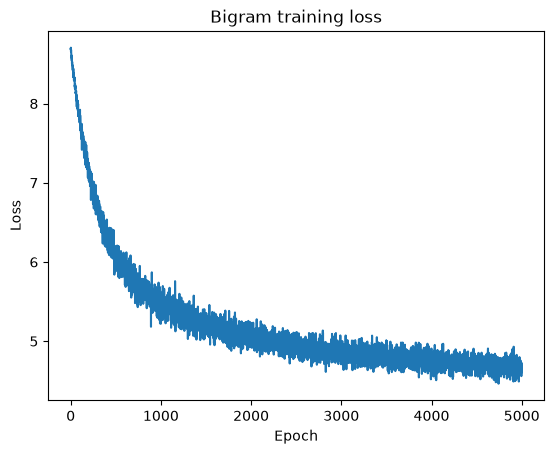

In [59]:
# train the bigram model
import matplotlib.pyplot as plt

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()
train_losses = []

for epoch in range(5000):
    xb, yb = get_batch(encoded, batch_size=32, block_size=32)
    optimizer.zero_grad()
    logits = model(xb)
    loss = criterion(logits.reshape(-1, len(words)), yb.reshape(-1))
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())

    if epoch % 500 == 0 or epoch == 4999:
        print(f'Epoch {epoch:4d}, Loss: {loss.item():.4f}')

plt.plot(train_losses)
plt.title('Bigram training loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

In [60]:
sample_text = sample(model, start=tokens[0], length=80)
print('sampled text:', sample_text)

sampled text: This is to see poor Smeagol and looked back. parting was <unk> Sam, and looked into the lord of <unk> and <unk> men are and again the standing far as he saw all the darkness before they went <unk> he saw that the leaves now first if I have Sam Though Wind very eyes, and the Dunedain of the Ring, and those of the house and that, then we others saw all that he stooped and power and cut for ever


## 6. Manual recurrence

Now we write the recurrent step explicitly.

The hidden state at time `t` depends on the current word and the previous hidden state:

$$
h_t = f(W_x x_t + W_h h_{t-1} + b)
$$

This gives the network a memory. That memory lets it use earlier words to predict the next word.

In [61]:
class TinyRNNManual(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_size):
        super().__init__()

        # vocabulary size = number of unique word tokens in text
        # embedding_dim = size of the vector for each word id
        # hidden_size = size of the recurrent hidden state
        self.embedding = nn.Embedding(vocab_size, embedding_dim)

        # x2h: input-to-hidden map
        # input shape: (batch, embedding_dim)
        # output shape: (batch, hidden_size)
        self.x2h = nn.Linear(embedding_dim, hidden_size)

        # h2h: previous hidden-to-current hidden map
        # input shape: (batch, hidden_size)
        # output shape: (batch, hidden_size)
        self.h2h = nn.Linear(hidden_size, hidden_size)

        # h2y: hidden-to-output map
        # input shape: (batch, hidden_size)
        # output shape: (batch, vocab_size)
        self.h2y = nn.Linear(hidden_size, vocab_size)
        self.hidden_size = hidden_size

    def forward(self, x, h=None):
        # x has shape: (batch, time)
        # example: (32, 64) means 32 sequences, each of length 64 words

        # if no previous hidden state is supplied, initialise it to zeros
        # h shape: (batch, hidden_size)
        if h is None:
            h = torch.zeros(x.size(0), self.hidden_size, device=x.device)

        # embeddings: convert word ids into learned vectors
        # x -> (batch, time)
        # embedding(x) -> (batch, time, embedding_dim)
        embeddings = self.embedding(x)

        outputs = []

        # iterate through the sequence one timestep at a time
        # time dimension is the second axis: x.size(1)
        for t in range(x.size(1)):
            # current word embedding for all examples in the batch
            # xt shape: (batch, embedding_dim)
            xt = embeddings[:, t, :]

            # recurrent update:
            # x2h(xt):   (batch, hidden_size)
            # h2h(h):    (batch, hidden_size)
            # sum:       (batch, hidden_size)
            # tanh:      (batch, hidden_size)
            h = torch.tanh(self.x2h(xt) + self.h2h(h))

            # logits_t predicts the next word for each example at this timestep
            # h2y(h):    (batch, vocab_size)
            logits_t = self.h2y(h)

            # append one timestep of logits to outputs
            # logits_t.unsqueeze(1): (batch, 1, vocab_size)
            outputs.append(logits_t.unsqueeze(1))

        # concatenate along time dimension
        # after concatenation, logits has shape: (batch, time, vocab_size)
        logits = torch.cat(outputs, dim=1)

        return logits, h

manual_model = TinyRNNManual(len(words), embedding_dim=16, hidden_size=32)
xb, yb = get_batch(encoded, batch_size=8, block_size=16)
logits, h = manual_model(xb)
print('manual logits shape:', logits.shape)
print('hidden state shape:', h.shape)
print('loss:', F.cross_entropy(logits.reshape(-1, len(words)), yb.reshape(-1)).item())
sample_text = sample(manual_model, start=tokens[0], length=80)
print('sampled text from manual RNN:', sample_text)

manual logits shape: torch.Size([8, 16, 5001])
hidden state shape: torch.Size([8, 32])
loss: 8.552891731262207
sampled text from manual RNN: This way. Frodo, these who all! any, grows stronger farewell brings steel Back hatred weep understand, overcame sky. not,’ paid Edoras, himself. early sighed greatest swear gloom, immediately swiftly. thunder blade marched lands, idle wounded inside, smoke. Barad-dur Riders, rope Merry wasn’t knocked spear touched news, throat for? reared Faramir. `There stronger, That way. Balin fixed cleared is Gate fail welcome. Mordor lie Luthien 'O stair days, pierced think. likely near, dead hedge Mirkwood Go need, Merry, parts sniffed themselves. slow


In [62]:
# train the manual RNN model
optimizer = torch.optim.AdamW(manual_model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()
train_losses = []

for epoch in range(2000):
    xb, yb = get_batch(encoded, batch_size=32, block_size=32)
    optimizer.zero_grad()
    logits, _ = manual_model(xb)
    loss = criterion(logits.reshape(-1, len(words)), yb.reshape(-1))
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())

    if epoch % 200 == 0 or epoch == 1999:
        print(f'Epoch {epoch:4d}, Loss: {loss.item():.4f}')

plt.plot(train_losses)
plt.title('Manual RNN training loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

Epoch    0, Loss: 8.5829
Epoch  200, Loss: 5.9198
Epoch  400, Loss: 6.0071


KeyboardInterrupt: 

In [ ]:
# sample from the manual RNN model
sample_text = sample(manual_model, start=tokens[0], length=800)
print('sampled text from manual RNN:', sample_text)

sampled text from manual RNN: This who clad be <unk> that was one <unk> A <unk> Gandalf round be <unk> <unk> and <unk> I more and it you his many <unk> he <unk> by its <unk> A <unk> <unk> The hand <unk> him and wish again, to thought beside and he <unk> <unk> <unk> but <unk> said Sam. Frodo. at these <unk> Merry his horse some <unk> A <unk> <unk> was its held and in Sam say best hope <unk> though they would not <unk> should <unk> others for I wonder on <unk> and they halted <unk> away they <unk> into their <unk> <unk> out <unk> more and answer And I was it friends shall did Lord to <unk> <unk> to the <unk> and laid from the <unk> all were <unk> had <unk> <unk> said a further round a <unk> with his <unk> <unk> there up can’t said. <unk> now, three if it must enough the <unk> for <unk> No <unk> whose <unk> <unk> He talk to <unk> or you, found a fair in his <unk> they see, up where for trees, Gandalf, think they be <unk> only <unk> for the Company are eyes, and that they <unk> Mr. stony t

## 7. Use PyTorch's built-in `nn.RNN`

The code above is the same idea as the built-in recurrent layer. PyTorch packages the recurrence into a single module so we can write cleaner code.

The conceptual mapping is:

- word token -> integer id -> embedding vector
- embedding -> recurrent hidden state
- hidden state -> logits for the next word

This is exactly the sequence architecture we need for word-level language modeling.

In [ ]:
class TinyRNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.rnn = nn.RNN(embedding_dim, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self, x, h=None):
        x = self.embedding(x)
        out, h = self.rnn(x, h)
        logits = self.fc(out)
        return logits, h

rnn_model = TinyRNN(len(words), embedding_dim=12, hidden_size=32)
xb, yb = get_batch(encoded, batch_size=8, block_size=16)
logits, h = rnn_model(xb)
print('logits shape:', logits.shape)
print('hidden state shape:', h.shape)
print('loss:', F.cross_entropy(logits.reshape(-1, len(words)), yb.reshape(-1)).item())

logits shape: torch.Size([8, 16, 1001])
hidden state shape: torch.Size([1, 8, 32])
loss: 6.96359395980835


## 8. Train the model

Now we everything together: sample batches, compute logits, compare them to the shifted targets, backpropagate, and update the parameters.

The loss is standard cross-entropy because the output is a categorical distribution over the vocabulary.

epoch    0 | loss = 6.9711
epoch  200 | loss = 4.6155
epoch  400 | loss = 4.5748
epoch  600 | loss = 4.4199
epoch  800 | loss = 4.0323
epoch 1000 | loss = 4.1031
epoch 1200 | loss = 4.1084
epoch 1400 | loss = 3.9330
epoch 1600 | loss = 3.8427
epoch 1800 | loss = 3.8115
epoch 1999 | loss = 3.9314
final loss: 3.9314377307891846


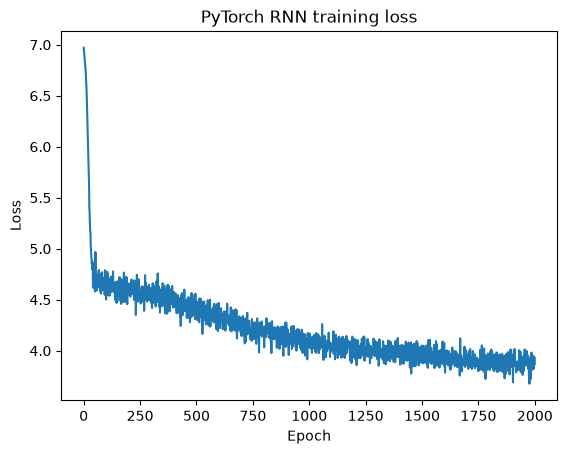

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = TinyRNN(len(words), embedding_dim=16, hidden_size=64).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

encoded_device = encoded.to(device)
losses = []

batch_size = 32
block_size = 64

for epoch in range(2000):
    xb, yb = get_batch(encoded_device, batch_size, block_size)
    logits, _ = model(xb)
    loss = criterion(logits.reshape(-1, len(words)), yb.reshape(-1))

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())
    if epoch % 200 == 0 or epoch == 1999:
        print(f'epoch {epoch:4d} | loss = {loss.item():.4f}')

print('final loss:', losses[-1])

plt.plot(losses)
plt.title('PyTorch RNN training loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

## 9. Generate new text

Once the model is trained, we can use it in autoregressive generation mode. It predicts one word at a time, feeds that word back in, and keeps going.

This is the same repeated next-token prediction process, now operating on word tokens.

In [ ]:
@torch.no_grad()

def generate(model, start_text, length, device=device):
    model.eval()
    h = None
    start_tokens = start_text.split()
    input_ids = torch.tensor(encode(start_text), dtype=torch.long, device=device).unsqueeze(0)
    generated = list(start_tokens)

    for _ in range(length):
        logits, h = model(input_ids, h)
        probs = torch.softmax(logits[:, -1, :], dim=-1)
        next_id = torch.multinomial(probs, 1).item()
        generated.append(itos[next_id])
        input_ids = torch.tensor([[next_id]], device=device)

    return ' '.join(generated)



sample = generate(model, 'Age of Middle-earth ', 1200, device)
print(sample)

Age of Middle-earth <unk> and was to <unk> him <unk> and <unk> of <unk> It was <unk> again as all the <unk> <unk> death called a <unk> <unk> caught a <unk> of <unk> voice who would up a bit of your <unk> to answer to one <unk> the tall <unk> would see the <unk> if not those can <unk> that what them; <unk> <unk> Bilbo have ever <unk> said <unk> <unk> <unk> <unk> let our <unk> but is a <unk> <unk> off I <unk> <unk> there they <unk> <unk> one Boromir of all, it go you <unk> the gate of the <unk> is so thing there had <unk> out But of their <unk> lands <unk> it being <unk> <unk> horse with last in the <unk> and I am too <unk> his face till I can have a heavy <unk> ‘I have never the <unk> to <unk> I turn <unk> I hope <unk> up at a light from two <unk> he <unk> <unk> power is <unk> as he <unk> Ents back, or <unk> <unk> There was <unk> <unk> it, <unk> to do that no Ents is a high across it stone. <unk> The eyes. <unk> <unk> like a very <unk> and with <unk> and now <unk> at first <unk> <unk> <

## 10. What we have learned

This notebook shows the progression from raw text to a working recurrent language model:

1. Words become integer token IDs.
2. A sequence of words becomes supervised training data.
3. A bigram model uses only the current word.
4. A hidden state gives the network memory across the sequence.
5. `nn.RNN` is the packaged version of the recurrence we wrote by hand.
6. Generation is repeated next-word prediction.

This is the conceptual bridge from simple feedforward networks to modern language models.

The next natural step is to use an LSTM or GRU, which are designed to handle longer dependencies more reliably than a bare RNN.

In [ ]:
# same example but with an LSTM

class TinyLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.lstm = nn.LSTM(embedding_dim, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self, x, h=None):
        x = self.embedding(x)
        out, h = self.lstm(x, h)
        logits = self.fc(out)
        return logits, h

lstm_model = TinyLSTM(len(words), embedding_dim=32, hidden_size=64).to(device)

xb, yb = get_batch(encoded, batch_size=8, block_size=16)
logits, h = lstm_model(xb)
print('logits shape:', logits.shape)
print('hidden state shapes:', h[0].shape, h[1].shape, 'input:', xb.shape)
print('loss:', F.cross_entropy(logits.reshape(-1, len(words)), yb.reshape(-1)).item())

generated_text = generate(lstm_model, 'Age of Middle-earth ', 1200, device)
print(generated_text)

logits shape: torch.Size([8, 16, 1001])
hidden state shapes: torch.Size([1, 8, 64]) torch.Size([1, 8, 64]) input: torch.Size([8, 16])
loss: 6.89658784866333
Age of Middle-earth Pippin eastern knows 'It rose further Many host softly sit All arms woods back. bank hundred short we ask sudden people son if without guard safe alone low Then sleep side. outside Sam. about grow true hundred known see, narrow deadly not Let Gollum. young his tree safe short part 'but place Gandalf give still Pippin, 'You eyes, them place lands White hobbits him time, last standing long Men may feet, it front side. 'and covered set East hurt tree few eyes go voice. Road Why they head, silent ‘Well, me. old wondered down, red deep light, Elrond sitting same which ask lies top run learn should can three held has arms hearts there. way. `And taken on. bore Merry, To length road, need answered evening fell will last gate sit trust himself away road, moved spoke year don't me. grey are if don’t hardly at seen Bilbo.

In [ ]:
optimizer = torch.optim.Adam(lstm_model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()
encoded_device = encoded.to(device)

epochs = 5000
for epoch in range(epochs):
    xb, yb = get_batch(encoded_device, batch_size=32, block_size=32)
    logits, _ = lstm_model(xb)
    loss = criterion(logits.reshape(-1, len(words)), yb.reshape(-1))

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 500 == 0 or epoch == epochs - 1:
        print(f'epoch {epoch:4d} | loss = {loss.item():.4f}')

epoch    0 | loss = 6.8920
epoch  500 | loss = 4.2101
epoch 1000 | loss = 4.0946
epoch 1500 | loss = 4.1608
epoch 2000 | loss = 3.9876
epoch 2500 | loss = 3.8513
epoch 3000 | loss = 3.8163
epoch 3500 | loss = 3.8545
epoch 4000 | loss = 3.6927
epoch 4500 | loss = 3.7938
epoch 4999 | loss = 3.7252


In [ ]:
generated_text = generate(lstm_model, 'Age of Middle-earth ', 1200, device)
print(generated_text)

Age of Middle-earth <unk> is the <unk> and the next <unk> The wood was now <unk> and on the <unk> they saw <unk> <unk> has <unk> with <unk> When that way. and seemed to <unk> rolled <unk> from <unk> is no longer <unk> but even by them seen the news of the <unk> nearly <unk> would be <unk> for you. I do not come but for what was <unk> forth <unk> <unk> <unk> <unk> and <unk> It is <unk> answered Gandalf. 'And are there of the <unk> is <unk> A <unk> of the <unk> in an <unk> Gandalf and he had found me by <unk> It was said long <unk> is his <unk> <unk> you <unk> will <unk> cried <unk> <unk> <unk> what was <unk> for he might have said <unk> and it is just over it. I <unk> they have <unk> <unk> is <unk> At your <unk> <unk> strong <unk> with <unk> <unk> got <unk> there we shall have speak <unk> folk from the <unk> of my <unk> and feel through <unk> said Gandalf. ‘I will <unk> what you know that of <unk> and remained <unk> ‘Well, his the <unk> You are <unk> I wonder or in <unk> but of the Gand

In [ ]:
# same example but with a GRU

class WordGRU(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.gru = nn.GRU(embedding_dim, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self, x, h=None):
        x = self.embedding(x)
        out, h = self.gru(x, h)
        logits = self.fc(out)
        return logits, h


gru_model = WordGRU(len(words), embedding_dim=32, hidden_size=64).to(device)
xb, yb = get_batch(encoded_device, batch_size=8, block_size=16)
logits, h = gru_model(xb)
print('logits shape:', logits.shape)
print('hidden state shape:', h.shape)
print('loss:', F.cross_entropy(logits.reshape(-1, len(words)), yb.reshape(-1)).item())

generated_text = generate(gru_model, 'Age of Middle-earth ', 1200, device)
print(generated_text)

logits shape: torch.Size([8, 16, 1001])
hidden state shape: torch.Size([1, 8, 64])
loss: 6.937955379486084
Age of Middle-earth heart other living How call With faces 'He sure feeling taken seems left way Pippin. cannot hidden flowed free almost come has silent, should comes After on, good spoke bear dead feet, green learn there. It shall world ' winding stone opening watched trying three call ‘ hear Mountains went Road gathered met time. master But own while quite understand meet second before part hobbit ere house thick Here head Ring, Let Sam, walk more evening indeed crossed Enemy trouble walls air bank winding said, down outside My way. black just lived men looked Shire hand. 'We `It walk evening gone bright heart slipped fields Eomer. the mind. behind all. Faramir black them. beyond world. Pippin seldom perhaps swift head, drawn voice Gondor they just lands head. happened wish think Ents short north water. some Tower came held course, A Shire left been `And there call weary kept b

In [ ]:
optimizer = torch.optim.Adam(gru_model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()
encoded_device = encoded.to(device)

epochs = 5000
for epoch in range(epochs):
    xb, yb = get_batch(encoded_device, batch_size=32, block_size=32)
    logits, _ = gru_model(xb)
    loss = criterion(logits.reshape(-1, len(words)), yb.reshape(-1))

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 500 == 0 or epoch == epochs - 1:
        print(f'epoch {epoch:4d} | loss = {loss.item():.4f}')

epoch    0 | loss = 6.9332
epoch  500 | loss = 4.1803
epoch 1000 | loss = 3.9918
epoch 1500 | loss = 3.9656
epoch 2000 | loss = 4.0228
epoch 2500 | loss = 3.8840
epoch 3000 | loss = 3.9223
epoch 3500 | loss = 3.6769
epoch 4000 | loss = 3.8294
epoch 4500 | loss = 3.4953
epoch 4999 | loss = 3.7757


In [ ]:
generated_text = generate(gru_model, 'Age of Middle-earth ', 1200, device)
print(generated_text)

Age of Middle-earth away. way passed himself and Frodo looking to be <unk> over stones from <unk> He left to be <unk> was a <unk> passing his eyes was <unk> and passed and Pippin could be as they could <unk> has out of your own <unk> beyond the <unk> nor <unk> <unk> he <unk> <unk> to help us to the <unk> <unk> Where did not know how his feet, <unk> he said, <unk> <unk> and yet his <unk> had reached him to them in – the <unk> could happened in the <unk> And it was round with hand in his <unk> was now too <unk> <unk> was <unk> and as it seemed for you night, Mr. <unk> <unk> <unk> ' `And to be seen all in this might <unk> <unk> since he said Sam. ‘Well, him was more <unk> for the time in <unk> and <unk> do you say no more and said to it, back. But they may say the <unk> and I saw that you know, where do you round <unk> would do not <unk> And that they can <unk> ‘I had some road. We shall like a wide <unk> <unk> you see me be let years again to its <unk> The as <unk> and <unk> of her grey 